# Identifying, validating, and steering induction circuits in GPT-2 Small with TransformerLens

---


### 09/2026 | Wolf Gautier
This notebook serves a dual purpose: it introduces the TransformerLens library as tooling to perform model analysis and intervention, and in parallel it finds and analyses induction heads in a model, illustrating how such a task can be approached with the TransformerLens library as well as introducing circuits conceptually.

Induction circuits were one of the earliest demonstrations of a human-readable algorithm within a model. In essence, these circuits display a deducible prediction procedure that generalises to text unseen in training data, demonstrating that transformer components, specifically attention, can transform into algorithmic structures.

This notebook identifies likely induction heads and previous-token heads through scoring, DLA and ablation, and then shows that an intervention on the output activations of the top $n$ previous-token heads by scoring can both have induction heads attend to a choosable different token set than normal and have the model output corresponding logits, allowing for targeted steering of model outputs themselves through modification of heads assumed to be a part of induction circuits, not induction heads themselves.

While not as state-of-the-art as they may have been when they were discovered, a pipeline for uncovering, validating and steering induction heads is still illustrative and a good way to become more familiar with tooling as well as a general approach.

In [ ]:
%pip install --upgrade transformer_lens==4.0.0 circuitsvis==1.43.3

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
import math
import circuitsvis as cv
from functools import partial
from collections import defaultdict
from tqdm.auto import tqdm
from transformer_lens.model_bridge import TransformerBridge
from transformer_lens.tools.analysis import direct_logit_attribution

torch.set_grad_enabled(False)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Illustrating the presence of induction circuits
Concretely, the following behaviour is being observed in transformer models: if a given sequence of tokens occurs more than once, the model is able to predict that sequence fairly well after having seen it the first time, even if the sequence itself is hard to predict. We can see whether this capability is present in a given model by creating a random sequence of tokens, concatenating two of the same sequence to have the random sequence repeated, and then computing its prediction loss over both halves of this total sequence.  

First, let's load a model and generate some random tokens.

In [ ]:
# Load a model (smallest version of GPT-2, 119M params)
model = TransformerBridge.boot_transformers("openai-community/gpt2", device=device)
model.enable_compatibility_mode()

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [ ]:
n_tokens_to_sample = 50
prefix = (torch.ones(1, 1) * model.tokenizer.bos_token_id).long() # GPT-2 used a prefix so it is needed here

# Sample from integers within the model's vocab dimensionality, then add twice
tokens = torch.randint(0, model.cfg.d_vocab, (1, n_tokens_to_sample))
input_tokens = torch.cat(
    [
        prefix,
        tokens,
        tokens
    ], dim=-1
)

# Truly random sequence for control
input_tokens_random = torch.cat(
    [
        prefix,
        torch.randint(0, model.cfg.d_vocab, (1, n_tokens_to_sample*2))
    ], dim=-1
)

# Print the generated text to ensure it is random
text = model.tokenizer.decode(input_tokens[0,1:])
print(f"\nText corresponding to obtained random tokens:\n\n{text}")


Text corresponding to obtained random tokens:

 injectingる showing glossy Atlantic dile fixing CBIolved cyn met blackCook mm boltsmale ace� educated capital purple Emmy Sync commem … Chain perpet virtual236center manned Erdogan Ont supporters thinks cling fluffyTG Contact thirstyLaterPro pillarsFloWikiIDS)))) announ confirmation1016 injectingる showing glossy Atlantic dile fixing CBIolved cyn met blackCook mm boltsmale ace� educated capital purple Emmy Sync commem … Chain perpet virtual236center manned Erdogan Ont supporters thinks cling fluffyTG Contact thirstyLaterPro pillarsFloWikiIDS)))) announ confirmation1016


Now, let's check to what extent the model's predicted logit probabilities match the true next token: we run the model sequentially on the given input sequence and check its cached logits for each step.

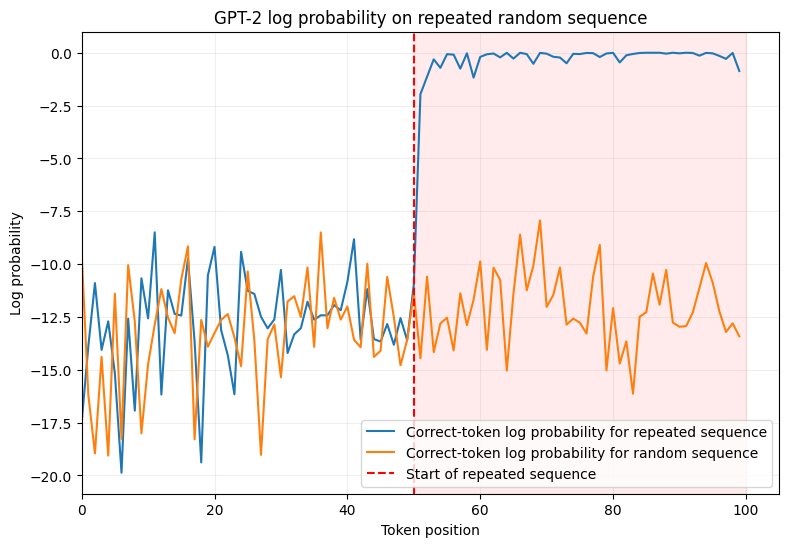

In [ ]:
# Run model and obtain log probabilities over vocabulary
logits, cache = model.run_with_cache(input_tokens)
logprobs = logits.log_softmax(dim=-1)

logits_random = model(input_tokens_random)
logprobs_random = logits_random.log_softmax(dim=-1)

# Find correct logprobs
correct_logprobs = logprobs[:, :-1].gather( # Align by target
    dim=-1,
    index=input_tokens[:, 1:].unsqueeze(-1), # Skip BOS token
).squeeze(-1)

correct_logprobs_random = logprobs_random[:, :-1].gather(
    dim=-1,
    index=input_tokens_random[:, 1:].unsqueeze(-1), # Skip BOS token
).squeeze(-1)

# Visualise
plt.figure(figsize=(9, 6))
plt.plot(
    correct_logprobs[0],
    linewidth=1.5,
    label="Correct-token log probability for repeated sequence"
)
plt.plot(
    correct_logprobs_random[0],
    linewidth=1.5,
    label="Correct-token log probability for random sequence"
)

plt.axvline(n_tokens_to_sample, color="red", linestyle="--", linewidth=1.5, label="Start of repeated sequence")
plt.axvspan(n_tokens_to_sample, len(correct_logprobs[0]), color="red", alpha=0.08)

plt.xlabel("Token position")
plt.xlim(0,)
plt.ylabel("Log probability")
plt.title("GPT-2 log probability on repeated random sequence")
plt.legend()
plt.grid(alpha=0.2)

We observe the mentioned interesting behaviour: the log probabilities the model predicts for the first occurrence of our random sequence are as expected inaccurate. However, even though the token sequence is by definition random and thus 1) not predictable and 2) unlikely to be like anything in its training data, there is a clearly visible jump in prediction accuracy when the sequence starts repeating itself.

The crucial takeaway here is that it would appear a **generalisable algorithm has emerged within the model's weights** during training that allows it to recognise recurring sequences. We can visually inspect the attention patterns to find indications of the mentioned pattern:

(this cell may take up to a minute to display the attention patterns)

In [ ]:
# Get layer 0 attention pattern of layer 5
attention_pattern = cache["pattern", 5][0]

str_tokens = model.tokenizer.convert_ids_to_tokens(
    input_tokens[0].tolist()
)

display(
    cv.attention.attention_patterns(
        tokens=str_tokens,
        attention=attention_pattern,
    )
)

It is visible that heads 1 and 5 of layer 5 exhibit exactly the pattern we described: the token at position $N_{sequence} + i$ attends strongly to the token at position $i + 1$, which is the token that followed the token at $i$ last time (verify it yourself: click on head 1 or 5 and then see which tokens in the later half of the sequence attend to in the earlier half of the sequence).

## Formalising induction head detection with hooks

---


This behaviour is nicely exact, so we could try to identify other heads in other layers that exhibit it too, as well as compute a metric for it instead of inspecting the attention patterns visually. Concretely, the algorithm we are suggesting is occurring is that when a recurring sequence of length $n_{rec}$ is present two or more times, a token that is part of that sequence occurring in the second or later instance of that sequence attends to the token that came after that token the first time:

$$
\text{attn}\space t_{\space i\space >\space n_{rec}} \rightarrow t_{\space i \space - \space n_{rec} \space+\space 1}.
$$

We can distill two other patterns from this which could be a part of this circuit if Q/K composition is occurring, which would be **tokens attending to the token directly behind them** and **tokens attending to the previous instance of that token:** a combination of these two simpler patterns could be written into what we see as the induction circuit as

$$
\boxed{\text{Induction}(i) \sim \text{PreviousToken} \circ \text{DuplicateToken}(i).}
$$

To find quantitative evidence of the presence of each of these three patterns, we should construct metrics or "scores" for each of them that we can compute on the attention patterns. Sticking to our testing format of feeding the model a randomly generated sequence concatenated with itself  happens to enable us to do so using diagonals for each of the three with different offsets: we could simply take the means of the attention scores at the diagonals we are interested in, as

$$
\begin{align}
\\
S_{\text{induction}} &= \text{mean}(\text{diag}(\text{attn}_{\space h, l}, \text{offset} = - n_{tokens} + 1)), \\
S_{\text{previous}} &= \text{mean}(\text{diag}(\text{attn}_{\space h, l}, \text{offset} = - 1)), \\
S_{\text{duplicate}} &= \text{mean}(\text{diag}(\text{attn}_{\space h, l}, \text{offset} = - n_{tokens})).\\
\\
\end{align}
$$

We should compute these scores for a given subset of sequence lengths and for $n$ random sequences per sequence length to reduce noise and ensure sequence length itself is not a factor. Instead of looping over a cache each time, we can do this with **hooks:** a core TransformerLens feature that lets us perform actions during the model's forward pass. We will do the following:
- loop over a subset of sequence lengths $l \in 16, 32, 64, 128$ and over $n$ concatenated duplicate random sequences of length $l \times 2$ for each sequence length
- determine for each loop an "induction score", a "previous token" score and a "duplicate token" score
- visualise the outcomes.

The following cell performs these actions, and the one after that visualises the mean outcomes for each head, for each score.


In [ ]:
seq_lens = [16, 32, 64, 128]
n_samples = 8 # increase if enough ram available!

# Create an empty dictionary to contain the attention scores
score_names = ["induction", "previous_token", "duplicate_token"]
score_results = {
    seq_len: {
        score_name: torch.empty(
            n_samples,
            model.cfg.n_layers,
            model.cfg.n_heads,
        )
        for score_name in score_names
    }
    for seq_len in seq_lens
}


def generate_duplicate_rand_tokens(
        bs,
        seq_len,
        vocab_size=model.cfg.d_vocab,
        start_token=model.tokenizer.bos_token_id,
        repeats=2
    ) -> torch.Tensor:
    """
    Create a tensor of shape [bs, seq_len * 2 + 1] containing sequences of the
    given start_token and a sequence of random tokens sampled from [0,
    vocab_size] twice, as [start_tok, seq, seq].
    """
    prefix = (torch.ones(bs, 1) * start_token).long()
    rand_tokens = torch.randint(0, vocab_size, (bs, seq_len))

    sequence = [prefix]
    for _ in range(repeats):
        sequence.append(rand_tokens)

    return torch.cat(sequence, dim=-1)


def attn_scores_hook(pattern, hook, seq_len, offsets, scores) -> None:
    """
    Compute attention-pattern scores for every head in one layer.

    Scores:
        induction: x_i^(2) -> x_{i+1}^(1)
        previous_token: x_i^(1) -> x_{i-1}^(1)
        duplicate_token: x_i^(2) -> x_i^(1)
    """
    layer = hook.layer()

    for score_name, offset in zip(scores.keys(), offsets):
        scores[score_name][:, layer] = pattern.diagonal(
            offset=offset,
            dim1=2,
            dim2=3
        ).mean(dim=-1)


# Lambda to have our the function only be applied to attention patterns
pattern_hook_filter = lambda name: name.endswith("attn.hook_pattern")

# Loop over sequence lengths
for seq_len in tqdm(seq_lens, desc="Sequence lengths"):

    # Generate repeated random sequences (batched)
    input_tokens = generate_duplicate_rand_tokens(bs=n_samples, seq_len=seq_len)

    # Compute offset values for each sequence length
    offsets = [
        -seq_len + 1, # Induction
        -1,           # Previous token
        -seq_len      # Duplicate token
    ]

    # Create a partial function with current params
    temp_hook_fn = partial(
        attn_scores_hook,
        seq_len=seq_len,
        offsets=offsets,
        scores=score_results[seq_len]
    )

    # Run the model with hooks
    model.run_with_hooks(
        input_tokens,
        fwd_hooks=[(pattern_hook_filter, temp_hook_fn)],
        return_type=None # Output is not relevant here, not returning it speeds up
    )


Sequence lengths:   0%|          | 0/4 [00:00<?, ?it/s]


  Top 10 heads with highest induction scores:
    1:    5.5
    2:    6.9
    3:    5.1
    4:    7.10
    5:    7.2
    6:    10.1
    7:    9.6
    8:    9.9
    9:    10.7
    10:    5.0

  Top 10 heads with highest previous_token scores:
    1:    4.11
    2:    3.7
    3:    6.8
    4:    2.2
    5:    5.6
    6:    3.2
    7:    2.9
    8:    3.8
    9:    2.5
    10:    3.6

  Top 10 heads with highest duplicate_token scores:
    1:    3.0
    2:    0.5
    3:    0.1
    4:    1.11
    5:    0.10
    6:    7.2
    7:    7.1
    8:    5.10
    9:    1.6
    10:    8.1


/tmp/ipykernel_5176/1527627849.py:102: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False)


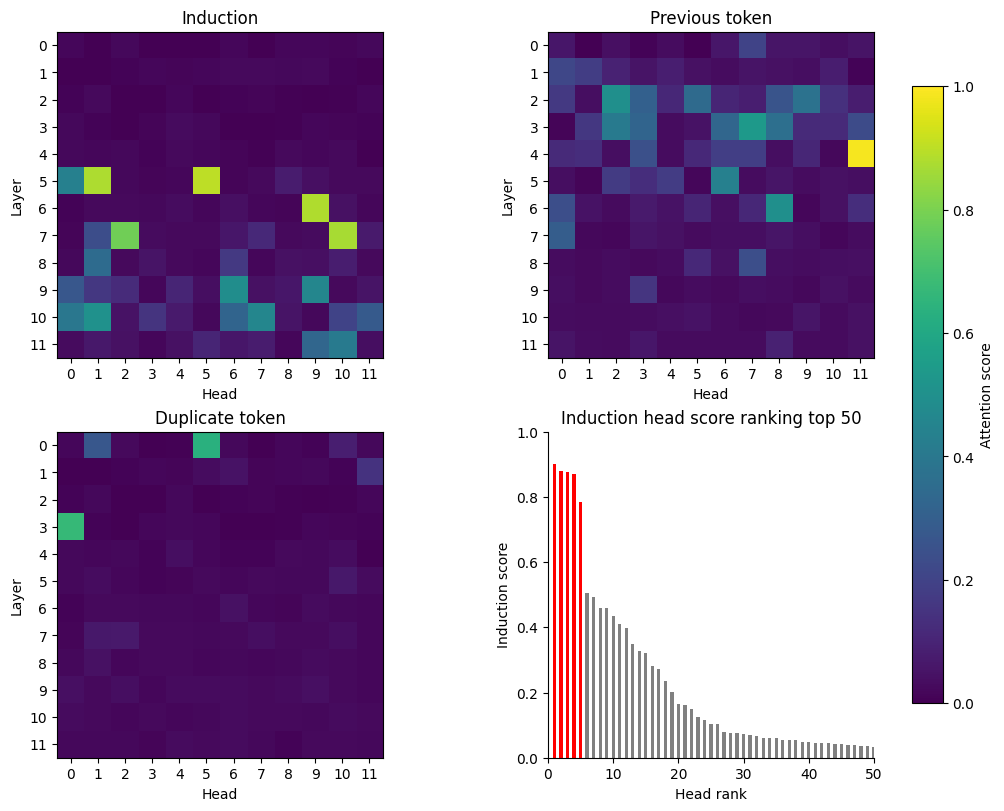

In [ ]:
scores = {
    "induction": torch.zeros((model.cfg.n_layers, model.cfg.n_heads)),
    "previous_token": torch.zeros((model.cfg.n_layers, model.cfg.n_heads)),
    "duplicate_token": torch.zeros((model.cfg.n_layers, model.cfg.n_heads)),
}

for seq_len, scores_tot in score_results.items():
    for score_type, score in scores_tot.items():
        scores[score_type] += score.mean(dim=0) / len(seq_lens)

# Compute top n highest scoring heads for each score
top_n = 10
suspected_heads = defaultdict(list)
for head_type, score in scores.items():
    values, flat_idx = torch.topk(score.flatten(), top_n)
    rows, cols = torch.unravel_index(flat_idx, score.shape)

    # Loop over all rows/cols
    print(f"\n  Top {top_n} heads with highest {head_type} scores:")
    for i, (row, col) in enumerate(zip(rows, cols)):
        suspected_heads[head_type].append((row.item(), col.item()))
        print(f"    {i+1}:    {row}.{col}")

n_layers, n_heads = scores["induction"].shape

induction = scores["induction"]

fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 8),
    constrained_layout=True,
)

heatmap_specs = [
    ("induction", "Induction"),
    ("previous_token", "Previous token"),
    ("duplicate_token", "Duplicate token"),
]

heatmap_axes = []

for ax, (score_name, title) in zip(axes.flat[:3], heatmap_specs):

    im = ax.imshow(
        scores[score_name],
        cmap="viridis",
        vmin=0,
        vmax=1,
        aspect="equal",
        interpolation="nearest",
    )

    ax.set_title(title)
    ax.set_xlabel("Head")
    ax.set_ylabel("Layer")

    ax.set_xticks(np.arange(n_heads))
    ax.set_yticks(np.arange(n_layers))

    heatmap_axes.append(ax)

ax = axes[1, 1]

all_heads = [
    (layer, head, induction[layer, head])
    for layer in range(n_layers)
    for head in range(n_heads)
]

all_heads.sort(key=lambda x: x[2], reverse=True)

ranked_scores = np.array([score for _, _, score in all_heads])
ranks = np.arange(1, len(ranked_scores) + 1, 1)

# Plot all remaining heads
ax.bar(
    ranks[5:],
    ranked_scores[5:],
    color="grey",
    width=.5
)

# Highlight top 5
ax.bar(
    ranks[:5],
    ranked_scores[:5],
    color="red",
    width=.5
)

ax.set_xlabel("Head rank")
ax.set_ylabel("Induction score")
ax.set_title("Induction head score ranking top 50")

ax.set_xlim(0, 50)
ax.set_ylim(0, 1)

ax.set_box_aspect(1)
ax.set_anchor("E")

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

cbar = fig.colorbar(
    im,
    ax=heatmap_axes,
    shrink=0.85,
    pad=0.03,
)

cbar.set_label("Attention score")

plt.show()

## Hypothesis
We find that heads 5.1, 5.5, 6.9, 7.2 and 7.10 present behaviour in line with the induction algorithm, 4.11 in line with the previous-token behaviour and 0.5 and 3.0 in line with the duplicate-token behaviour. We could now pose the hypothesis that **the induction circuit-like behaviour observed in GPT-2-Small follows from interactions between these upstream heads and the observed induction behaviour-exhibiting heads,** potentially through composition, as

$$
\boxed{
H^{4.11}, H^{0.5}, H^{3.0} \rightarrow H^{5.1}, H^{5.5}, H^{6.9}, H^{7.2}, H^{7.10}.
}
$$

We can perform three sub-experiments to verify this:
- **Logit attribution:** if the observed behaviour holds, then the induction heads should directly promote the induction-predicted token. How much do they actually contribute to the final log probability of the correct token?
- **Ablation of the found heads:** does manually adjusting/hiding the attention of the heads proposed to create the induction behaviour reduce it?
- **Induction steering:** if the observed induction heads and the upstream heads directly contribute to the observed induction behaviour through the proposed Q/K-composition, could adjusting a component of the proposed structure be used to have the induction circuit promote different tokens according to a manually specified algorithm?




## Logit attribution
---
We aim to determine what contributions the heads we stated seemed like attention heads actually have to the logits of the tokens predicted through an induction circuit. We can concretely look at the **difference in attribution between the first and later occurrences of a repeated token,** where a direct increase in the logit for $x_{n+i}$ compared to $x_{i}$ attributable to one of the suspected induction heads could suggest that that particular head is partaking in an induction circuit or using the information of one downstream.

To do so, we again generate $n$ sequences containing repeated sub-sequences of random tokens, such that a sequence is structured as

$$
[BOS, \space T_{rand}, \space T_{rand}],
$$

where $BOS$ is the beginning-of-sequence token GPT-2 works with, and $T_{rand}$ is a sequence of tokens randomly generated from the model vocabulary of length $n_{\text{random tokens}}.$ We then feed these to the model, after which we perform direct logit attribution on the model cache, but separately for both occurrences of the repeated sequence, so on tokens $[1:\text{sequence length}]$ and $[\text{sequence length} + 1: 2\times \text{sequence length}].$

 For all runs, we can take the mean of the logit contributions over all generated sequences and all tokens in these two halves of the total input sequence for each head, and check for which heads the difference between logit contributions between the first and second occurrences of a token is the biggest.

In [ ]:
seq_len = 64
n_samples = 8 # increase if enough ram available!
bs = 8

# Generate random tokens
tokens_batched = generate_duplicate_rand_tokens(bs=n_samples, seq_len=seq_len, repeats=2)

In [ ]:
n_components = model.cfg.n_layers * model.cfg.n_heads + 1
n_positions = seq_len - 1

dla_first_seq = torch.empty((n_components, n_samples, n_positions))
dla_second_seq = torch.empty((n_components, n_samples, n_positions))

labels = None

# Loop over minibatches of our total random sequences to manage RAM usage
with torch.inference_mode():
    for start in tqdm(range(0, n_samples, bs)):
        end = min(start + bs, n_samples)

        batch_tokens = tokens_batched[start:end]

        # Obtain cache from model
        _, cache = model.run_with_cache(batch_tokens)

        # Obtain dla for both occurrences of the repeated sequence
        dla_first_curr = direct_logit_attribution(
            model,
            answer_tokens=batch_tokens[:, 2:seq_len + 1],
            unit="head",
            pos=slice(1, seq_len),
            cache=cache,
        )

        dla_second_curr = direct_logit_attribution(
            model,
            answer_tokens=batch_tokens[:, seq_len + 2 : 2 * seq_len + 1],
            unit="head",
            pos=slice(seq_len + 1, 2 * seq_len),
            cache=cache,
        )

        if labels is None:
            labels = dla_first_curr.labels

        dla_first_seq[:, start:end] = (dla_first_curr.attribution).detach().cpu()
        dla_second_seq[:, start:end] = (dla_second_curr.attribution).detach().cpu()

        del cache
        del dla_first_curr
        del dla_second_curr

  0%|          | 0/1 [00:00<?, ?it/s]

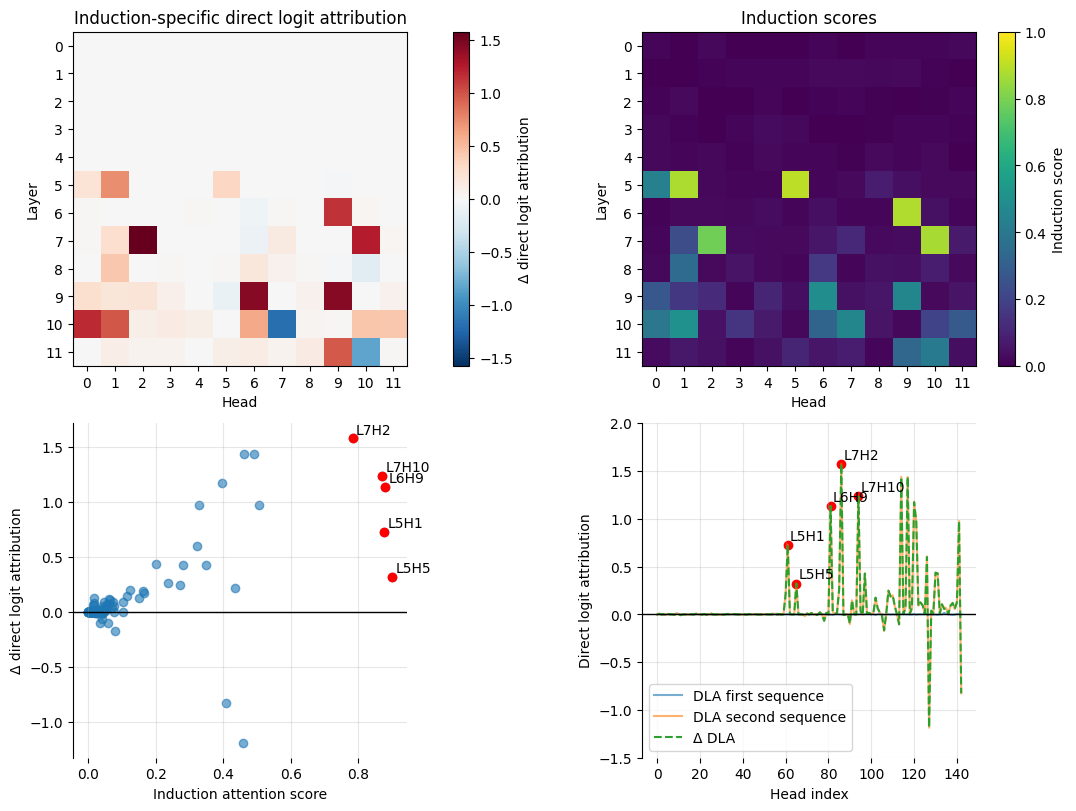

In [ ]:
delta = dla_second_seq - dla_first_seq
delta_mean = delta.mean(dim=(1,2))

head_mask = [
    i for i, label in enumerate(labels)
    if label.startswith("L") and "H" in label
]

ind_head_indices = [61, 65, 81, 86, 94]

mean_delta = delta.mean(dim=(1, 2))
head_delta = mean_delta[head_mask]

delta_matrix = head_delta.reshape(
    model.cfg.n_layers,
    model.cfg.n_heads
)

vmax = delta_matrix.abs().max().item()


fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 8),
    constrained_layout=True,
)

im = axes[0, 0].imshow(
    delta_matrix.detach().cpu(),
    cmap="RdBu_r",
    vmin=-vmax,
    vmax=vmax,
)

plt.colorbar(im, label="Δ direct logit attribution")
axes[0, 0].set_xlabel("Head")
axes[0, 0].set_ylabel("Layer")
axes[0, 0].set_xticks(np.arange(n_heads))
axes[0, 0].set_yticks(np.arange(n_layers))
axes[0, 0].set_title("Induction-specific direct logit attribution")

im = axes[0, 1].imshow(
        scores["induction"],
        cmap="viridis",
        vmin=0,
        vmax=1,
        aspect="equal",
        interpolation="nearest",
)

axes[0, 1].set_title("Induction scores")
axes[0, 1].set_xlabel("Head")
axes[0, 1].set_ylabel("Layer")
plt.colorbar(im, label="Induction score")


axes[0, 1].set_xticks(np.arange(n_heads))
axes[0, 1].set_yticks(np.arange(n_layers))


x = scores["induction"].flatten().detach().cpu()
y = head_delta.detach().cpu()

im = axes[1, 0].scatter(x, y, alpha=0.6)

for idx in ind_head_indices:
    layer = idx // model.cfg.n_heads
    head = idx % model.cfg.n_heads

    axes[1, 0].scatter(
        x[idx],
        y[idx],
        color="red",
        zorder=3,
    )

    axes[1, 0].annotate(
        f"L{layer}H{head}",
        (x[idx] + .01, y[idx] + .04),
    )


axes[1, 0].set_xlabel("Induction attention score")
axes[1, 0].set_ylabel("Δ direct logit attribution")
axes[1, 0].axhline(0, color="black", linewidth=1)
axes[1, 0].spines[["top", "right", "bottom"]].set_visible(False)
axes[1, 0].grid(alpha=0.3)
axes[1, 0].set_box_aspect(1)
axes[1, 0].set_anchor("E")

axes[1, 1].plot(dla_first_seq.mean(dim=(1,2))[:143], alpha=0.6, label="DLA first sequence")
axes[1, 1].plot(dla_second_seq.mean(dim=(1,2))[:143], alpha=0.6, label="DLA second sequence")
axes[1, 1].plot(delta_mean[:143], '--', label="Δ DLA")

for idx in ind_head_indices:
    layer = idx // model.cfg.n_heads
    head = idx % model.cfg.n_heads

    axes[1, 1].annotate(
        f"L{layer}H{head}",
        (idx + 1., delta_mean[idx] + .05),
    )

axes[1, 1].set_xlabel("Head index")
axes[1, 1].set_ylabel("Direct logit attribution")
axes[1, 1].set_ylim(-1.5, 2)
axes[1, 1].axhline(0, color="black", linewidth=1)
axes[1, 1].spines[["top", "right", "bottom"]].set_visible(False)
axes[1, 1].grid(alpha=0.3)
axes[1, 1].legend()
axes[1, 1].set_box_aspect(1)
axes[1, 1].set_anchor("E")

axes[1, 1].scatter(ind_head_indices, delta.mean(dim=(1,2))[ind_head_indices], color='red')


We observe that the first five heads with a significant positive correct logit contribution delta across the first and second occurrence of tokens are the heads we previously identified as those having the largest "induction scores", namely 5.1, 5.5, 6.9, 7.2 and 7.10.

There are other heads that have substantial (negative) contribution deltas, such as 10.7, but all of these are downstream from the five named heads. These could therefore be part of circuits involving the outputs of the five named induction heads, in which case ablation of these 5 should directly affect their deltas too.

## Ablation
---
Having identified that the heads displaying a large induction score do in fact contribute to logits when a sequence has been seen before both meaningfully and meaningfully different from how they did on the first occurrence of the sequence, we can now assert whether their contributions to the residual stream are the main thing enabling the model to exhibit induction behaviour through ablation. This entails modifying the output activations of those heads of the model mid-inference, effectively removing access to the information they would otherwise contain for heads and computations downstream from them, and checking to what extent doing so affects the model's capacity to predict the recurring but random tokens. Specifically, we will mean-ablate:

- the heads with the top 5 highest induction scores,
- the heads with the top 5 highest previous-token scores,
- the heads with the top 5 highest duplicate-token scores, and
- all 15 of these heads at once.

We will perform two control runs:

- a run with the same repeated tokens as in the ablated runs but with all heads untouched, and
- a run on a completely random sequence of the same length, also with all heads untouched.

This will allow us to compare the model performance with and without the information these heads provide directly. We can also visualise the differences on a per-token basis, taking only the mean over the batched sequences.

In [ ]:
n_heads_to_ablate = 5
heads_to_ablate = {head_type: heads[:n_heads_to_ablate] for head_type, heads in suspected_heads.items()}

head_means = defaultdict(lambda: defaultdict(dict))

# Generate random non-repeated tokens for mean computation
random_tokens = generate_duplicate_rand_tokens(
    bs=bs,
    seq_len=seq_len * 2,
    repeats=1,
)

# Obtain means per head from non-ablated forward pass cache
with torch.no_grad():
    logits_random_control, cache = model.run_with_cache(random_tokens)

#for head_type, attn_heads in suspected_heads.items():
for head_type, attn_heads in heads_to_ablate.items():
    for layer, head in attn_heads:

        z = cache[f"blocks.{layer}.attn.hook_z"]

        # [d_head]
        mean_activation = z[:, :, head, :].mean(dim=(0, 1))

        head_means[head_type][layer][head] = (
            mean_activation.detach()
        )

In [ ]:
def head_mean_ablation_hook(z, hook, heads):
    z = z.clone()
    for head_idx, mean_activation in heads.items():
        z[:, :, head_idx, :] = mean_activation

    return z


ablation_hooks = {}
for head_type, layers in head_means.items():
    hooks = []
    for layer, heads in layers.items():
        hooks.append(
            (
                f"blocks.{layer}.attn.hook_z",
                partial(
                    head_mean_ablation_hook,
                    heads=heads,
                ),
            )
        )
    ablation_hooks[head_type] = hooks

In [ ]:
ablated_logits = {}

with torch.no_grad():
    all_hooks = []
    for head_type, hooks in ablation_hooks.items():
        ablated_logits[head_type] = model.run_with_hooks(
            tokens_batched,
            fwd_hooks=hooks,
        )
        all_hooks.extend(hooks)

    ablated_logits["total"] = model.run_with_hooks(
        tokens_batched,
        fwd_hooks=all_hooks,
    )

    logits_non_ablated = model(tokens_batched)

In [ ]:
def get_correct_logprobs(logits, target_tokens, offset=1):
    """
    Returns the log-probability of the target token `offset` positions
    after each prediction position.

    Args:
        logits: [batch, sequence_length, vocab_size]
        target_tokens: [batch, sequence_length]
        offset: Number of positions ahead to score. Default is 1.

    Returns:
        [batch, sequence_length - offset]
    """
    logprobs = logits.log_softmax(dim=-1)

    return (
        logprobs[:, :-offset].gather(
            dim=-1,
            index=target_tokens[:, offset:].unsqueeze(-1),
        ).squeeze(-1)
    )



def get_induction_gain(correct_logprobs, seq_len, offset=1):
    """
    Compare the same transitions in first and second instances of a repeated
    sequence.

    Returns one induction-gain value per sequence: [batch].
    """
    first_seq = correct_logprobs[:, offset:seq_len]
    second_seq = correct_logprobs[:, seq_len + 1:]

    return (second_seq - first_seq).mean(dim=-1)


correct_logprobs_non_ablated = get_correct_logprobs(logits_non_ablated, tokens_batched)

correct_logprobs_random_control = get_correct_logprobs(logits_random_control, random_tokens)

correct_logprobs_ablated = {
    condition: get_correct_logprobs(logits, tokens_batched)
    for condition, logits in ablated_logits.items()
}

clean_gain = get_induction_gain(correct_logprobs_non_ablated, seq_len)

random_control_gain = get_induction_gain(correct_logprobs_random_control, seq_len)

ablated_gains = {
    condition: get_induction_gain(correct_logprobs, seq_len)
    for condition, correct_logprobs in correct_logprobs_ablated.items()
}

clean_gain_mean = clean_gain.mean().item()
random_control_gain_mean = random_control_gain.mean().item()


ablation_results = {}

for condition, gain in ablated_gains.items():
    gain_mean = gain.mean().item()
    effect = clean_gain_mean - gain_mean

    ablation_results[condition] = {
        "gain": gain_mean,
        "effect": effect
    }

mean_clean = correct_logprobs_non_ablated.mean(dim=0)
mean_random = correct_logprobs_random_control.mean(dim=0)

mean_ablated = {
    condition: values.mean(dim=0).detach().cpu()
    for condition, values in correct_logprobs_ablated.items()
}

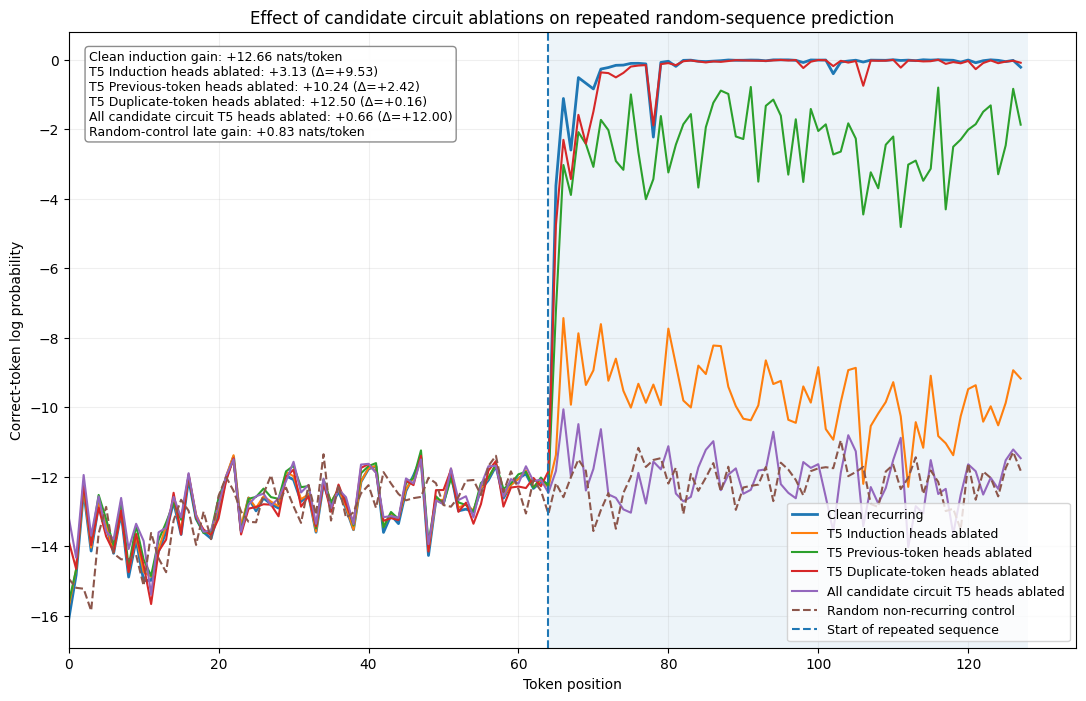

In [ ]:
fig, ax = plt.subplots(figsize=(13, 8))

# Clean recurring sequence
ax.plot(
    mean_clean,
    linewidth=2.0,
    label="Clean recurring",
)

# Individual ablation conditions
real_names = {
    "induction": "T5 Induction heads ablated",
    "previous_token": "T5 Previous-token heads ablated",
    "duplicate_token": "T5 Duplicate-token heads ablated",
    "total": "All candidate circuit T5 heads ablated",
}

for condition, values in mean_ablated.items():

    ax.plot(
        values,
        linewidth=1.5,
        label=real_names.get(condition, condition),
    )

# Random non-repeating control
ax.plot(
    mean_random,
    linewidth=1.5,
    linestyle="--",
    label="Random non-recurring control",
)

# Beginning of repeated copy
ax.axvline(
    seq_len,
    linestyle="--",
    linewidth=1.5,
    label="Start of repeated sequence",
)

ax.axvspan(
    seq_len,
    len(mean_clean),
    alpha=0.08,
)

metric_lines = [
    f"Clean induction gain: {clean_gain_mean:+.2f} nats/token",
]

for condition, result in ablation_results.items():

    name = real_names.get(condition, condition)

    metric_lines.append(
        f"{name}: "
        f"{result['gain']:+.2f} "
        f"(Δ={result['effect']:+.2f})"
    )

metric_lines.append(
    f"Random-control late gain: "
    f"{random_control_gain_mean:+.2f} nats/token"
)

metric_text = "\n".join(metric_lines)

ax.text(
    0.02,
    0.97,
    metric_text,
    transform=ax.transAxes,
    va="top",
    ha="left",
    fontsize=9,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="grey",
        alpha=0.9,
    ),
)

ax.set_xlabel("Token position")
ax.set_ylabel("Correct-token log probability")
ax.set_xlim(0)

ax.set_title(
    "Effect of candidate circuit ablations on repeated random-sequence prediction"
)

ax.legend(
    loc="lower right",
    fontsize=9,
)

ax.grid(alpha=0.2)

plt.show()

We observe a few things of note here. Firstly, as seen before, the model is able to predict the previously occurring random tokens very well as-is, and as expected is unable to predict a sequence of fully random tokens. Some gain in correct-token log probability is still seen for the random sequence, which may be attributable to the model preseneting generally more equalised log probabilities later on in the random sequence, leaning less towards suggesting more frequently occurring tokens.

Secondly, we observe that ablating the heads with a top 5 induction score drastically reduces the model's performance by about 10 nats, and ablating the top 5 heads based on induction score, previous-token score and duplicate-token score together reduces the model's performance down to almost exactly that of the random control sequence. This suggests that the observed ability of the model to correctly predict random but recurring sequences seems to stem very largely from the heads we identified as induction heads, and from the heads we hypothesised to be part of the total induction circuit. However, we also idenfity that ablating the top 5 duplicate-token heads alone has little to no effect on the induction capacity, meaning the main performance decrease may stem from the combination of previous-token heads and induction heads.

Thirdly, we observe that ablating only the top 5 previous token heads also affects induction capacity in a significant way, decreasing correct-token log probabilities from near-zero to about -2.5. While this decrease is less significant than ablating the induction heads themselves, implying that the model is still able to obtain a portion of the information they provide elsewhere, it does suggest these heads play a role in the sequence as a whole.


## Steering: manual adjustment of previous-token heads
---
We can now perform an experiment. We have observed both that ablating the heads we identified as induction heads reduced the model's "induction capacity" significantly, and that leaving those untouched but ablating the previous-token heads also significantly affected that capacity, albeit less so. This could indicate that at least the previous-token head $↔$ induction head-composition part of our hypothesis holds up; the induction heads seem largely responsible for the model's induction capacity, and the previous-token heads seem to be needed to enable the induction heads to perform induction properly. Previous-token heads have a fairly strict $n-1$ diagonal attention pattern: if this pattern is indeed used by induction heads, could we manually modify that pattern to affect the behaviour of induction heads without modifying them directly?

Concretely, if the algorithm we predicted

$$
T_{induction} \sim H_{previous} \circ H_{duplicate}
$$

holds at least partially for a dependence on $H_{previous},$ modifying those heads to point not to a previous token but to a different one, say one $n$ positions offset from the actual previous token, should lead to the induction heads changing which token they attend to, and, since we established the induction heads to contribute significantly to the final log probabilities on random but repeated sequences, the model should "move" some log probability from the usual induction-suggested token to the one we made the previous-token head point to.

We can implement this, having visually inspected the heads we previously deemed previous-token heads to have a diagonal attention pattern at $n-1,$ by taking the attention those heads have at this previous-token index and moving that to a token offset by $n$ positions, only for the first instances of the repeated sequence as $i_T < L_{seq} + 1.$ We thus only modify the exact parts of the attention patterns we hypothesised made up a part of the induction circuit.

In [ ]:
n_heads_to_shift = 10
heads_to_shift = {head_type: heads[:n_heads_to_shift] for head_type, heads in suspected_heads.items()}

offset = 1
alpha = 1.0
max_offset = max(3, offset)

prev_by_layer = defaultdict(list)
for layer, head in heads_to_shift["previous_token"]:
    prev_by_layer[layer].append(head)

induction_heads = heads_to_shift["induction"]
induction_layers = {layer for layer, _ in induction_heads}

# Clean run for comparison
with torch.inference_mode():
    logits_clean, cache_clean = model.run_with_cache(tokens_batched)


def previous_token_shift_hook(
        pattern,
        hook,
        offset=offset,
        alpha=alpha,
        steered_patterns=None,
        save_pattern=False
    ):
    """
    Takes the attention assigned by heads suspected of being previous-token
    heads to the previous token and moves a fraction of it to the token at
    position previous + n for tokens within the first instance of a repeated
    sequence.
    Args:
        offset: how many positions to offset attention values by
        alpha: how much of the attention to move (0 < alpha < 1)
    """
    layer = hook.layer()
    out = pattern

    # Only change attention of suspected previous-token heads
    if layer in prev_by_layer:
        out = pattern.clone()

        # First-seq destinations for which j-1-n is still in first seq
        j = torch.arange(offset + 2, seq_len + 1)

        for head in prev_by_layer[layer]:

            # Move alpha of the existing previous-token attention
            attn_val = alpha * out[:, head, j, j - 1].clone()

            out[:, head, j, j - 1] -= attn_val
            out[:, head, j, j - 1 - offset] += attn_val

    # Save downstream induction patterns for analysis
    if layer in induction_layers and save_pattern == True:
        steered_patterns[layer] = out.detach().clone()

    return out


with torch.inference_mode():
    logits_steered = model.run_with_hooks(
        tokens_batched,
        fwd_hooks=[
            (pattern_hook_filter, previous_token_shift_hook)
        ],
    )

In [ ]:
offset_logprobs_non_ablated = get_correct_logprobs(
    logits_non_ablated, tokens_batched, offset=offset + 1
)

correct_logprobs_modified_heads = get_correct_logprobs(
    logits_steered, tokens_batched, offset=1
)

offset_logprobs_modified_heads = get_correct_logprobs(
    logits_steered, tokens_batched, offset=offset + 1
)


offset_non_ablated_gain = get_induction_gain(
    torch.cat(
        [offset_logprobs_non_ablated, torch.full(
                (n_samples, 1),
                -math.log(model.cfg.d_vocab),
            )
        ],
        dim=1
    ),
    seq_len,
    offset=1
).mean().item()
correct_ablated_gain = get_induction_gain(
    correct_logprobs_modified_heads,
    seq_len,
    offset=1
).mean().item()
offset_ablated_gain = get_induction_gain(
    torch.cat(
        [offset_logprobs_modified_heads, torch.full(
                (n_samples, 1),
                -math.log(model.cfg.d_vocab),
            )
        ],
        dim=1
    ),
    seq_len,
    offset=1
).mean().item()

metric_text_mod = f"""Clean induction gain (correct token): {clean_gain_mean:+.2f} nats/token
Clean induction gain (correct token + 1): {offset_non_ablated_gain:+.2f} (Δ={clean_gain_mean - offset_non_ablated_gain:+.2f})
Modified induction gain (correct token): {correct_ablated_gain:+.2f} (Δ={clean_gain_mean - correct_ablated_gain:+.2f})
Modified induction gain (correct token + 1): {offset_ablated_gain:+.2f} (Δ={clean_gain_mean - offset_ablated_gain:+.2f})
Random-control late gain: {random_control_gain_mean:+.2f} nats/token
"""
print(metric_text_mod)

Clean induction gain (correct token): +12.66 nats/token
Clean induction gain (correct token + 1): -8.07 (Δ=+20.73)
Modified induction gain (correct token): -2.58 (Δ=+15.23)
Modified induction gain (correct token + 1): +12.21 (Δ=+0.45)
Random-control late gain: +0.83 nats/token



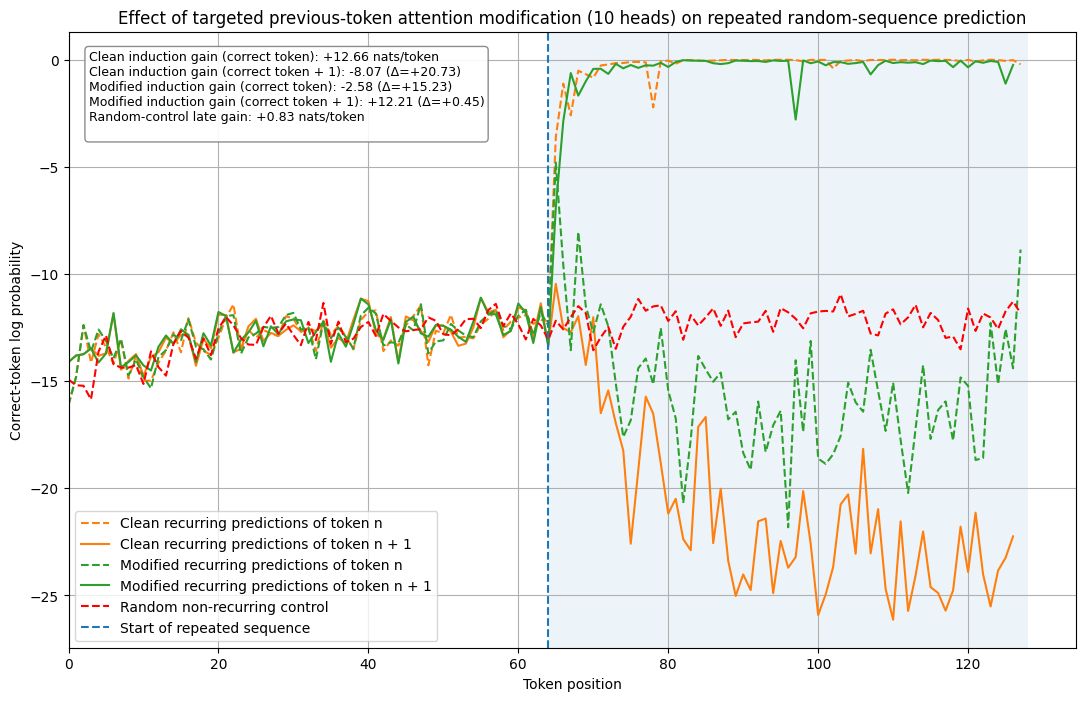

In [ ]:
# Visualise
fig, ax = plt.subplots(figsize=(13, 8))

ax.text(
    0.02,
    0.97,
    metric_text_mod,
    transform=ax.transAxes,
    va="top",
    ha="left",
    fontsize=9,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="grey",
        alpha=0.9,
    ),
)

ax.plot(
    mean_clean,
    color="tab:orange",
    linestyle="--",
    linewidth=1.5,
    label="Clean recurring predictions of token n",
)

ax.plot(
    offset_logprobs_non_ablated.mean(dim=0),
    color="tab:orange",
    linewidth=1.5,
    label="Clean recurring predictions of token n + 1",
)

ax.plot(
    correct_logprobs_modified_heads.mean(dim=0),
    color="tab:green",
    linestyle="--",
    linewidth=1.5,
    label="Modified recurring predictions of token n",
)

ax.plot(
    offset_logprobs_modified_heads.mean(dim=0),
    color="tab:green",
    linewidth=1.5,
    label=f"Modified recurring predictions of token n + {offset}",
)

ax.plot(
    mean_random,
    color="red",
    linewidth=1.5,
    linestyle="--",
    label="Random non-recurring control",
)

ax.axvline(
    seq_len,
    linestyle="--",
    linewidth=1.5,
    label="Start of repeated sequence",
)

ax.axvspan(
    seq_len,
    len(mean_clean),
    alpha=0.08,
)

ax.set_xlabel("Token position")
ax.set_ylabel("Correct-token log probability")
ax.set_xlim(0)

ax.set_title(
    f"Effect of targeted previous-token attention modification ({n_heads_to_shift} heads) on repeated random-sequence prediction"
)
ax.grid()
ax.legend()

We observe that the targeted intervention with $\text{offset} = 1$ on the 10 heads with the highest "previous-token score" as determined earlier lets us have the model exhibit very similar behaviour to the existing induction characteristics, but on the token after the one a typical induction circuit would predict. Firstly, the mean log probabilities of the token 1 position after the usual induction position of the model with modified attention are just 0.3 nats less than that of the non-modified model on the usual induction indices, which is a gain of 12.5 nats compared to the first sequence occurrence, and is also close to 0 again meaning the model confidently predicts the tokens we steered it towards with our intervention. Secondly, we see that the non-modified model presents log probabilities for tokens at $n+1$ during the second sequence occurrence that are lowered compared to the first sequence occurrence by about 10 nats. The modified model presents this same behaviour in a slightly reduced quantity but similar structure: it is now confident in the tokens at $n+1$ being correct and confident in the tokens at $n$ being wrong!

We can now perform a small grid search over numbers of previous-token heads to modify and offsets to try and generalise the observed behaviour. Specifically, we will compute and look at this offset intervention applied to the top 1, 5 and 10 previous-token-scoring heads, and offsets 1 and 2.

In [ ]:
n_heads_shift_options = [1, 5, 10]
offset_options = [1, 2]
max_offset = 3
multi_offset_mod_results = defaultdict(lambda: defaultdict(dict))

induction_heads = suspected_heads["induction"][:max(n_heads_shift_options)]
induction_layers = {layer for layer, _ in induction_heads}


with tqdm(total=len(n_heads_shift_options) * len(offset_options)) as pbar:
    for n_heads_to_shift in n_heads_shift_options:
        prev_by_layer = defaultdict(list)
        for layer, head in suspected_heads["previous_token"][:n_heads_to_shift]:
            prev_by_layer[layer].append(head)

        for offset in offset_options:
            result = multi_offset_mod_results[n_heads_to_shift][offset]
            hook_fn = partial(previous_token_shift_hook, offset=offset, steered_patterns=result, save_pattern=True)
            result["logits"] = model.run_with_hooks(
                tokens_batched, fwd_hooks=[(pattern_hook_filter, hook_fn)]
            )
            pbar.update(1)

  0%|          | 0/6 [00:00<?, ?it/s]

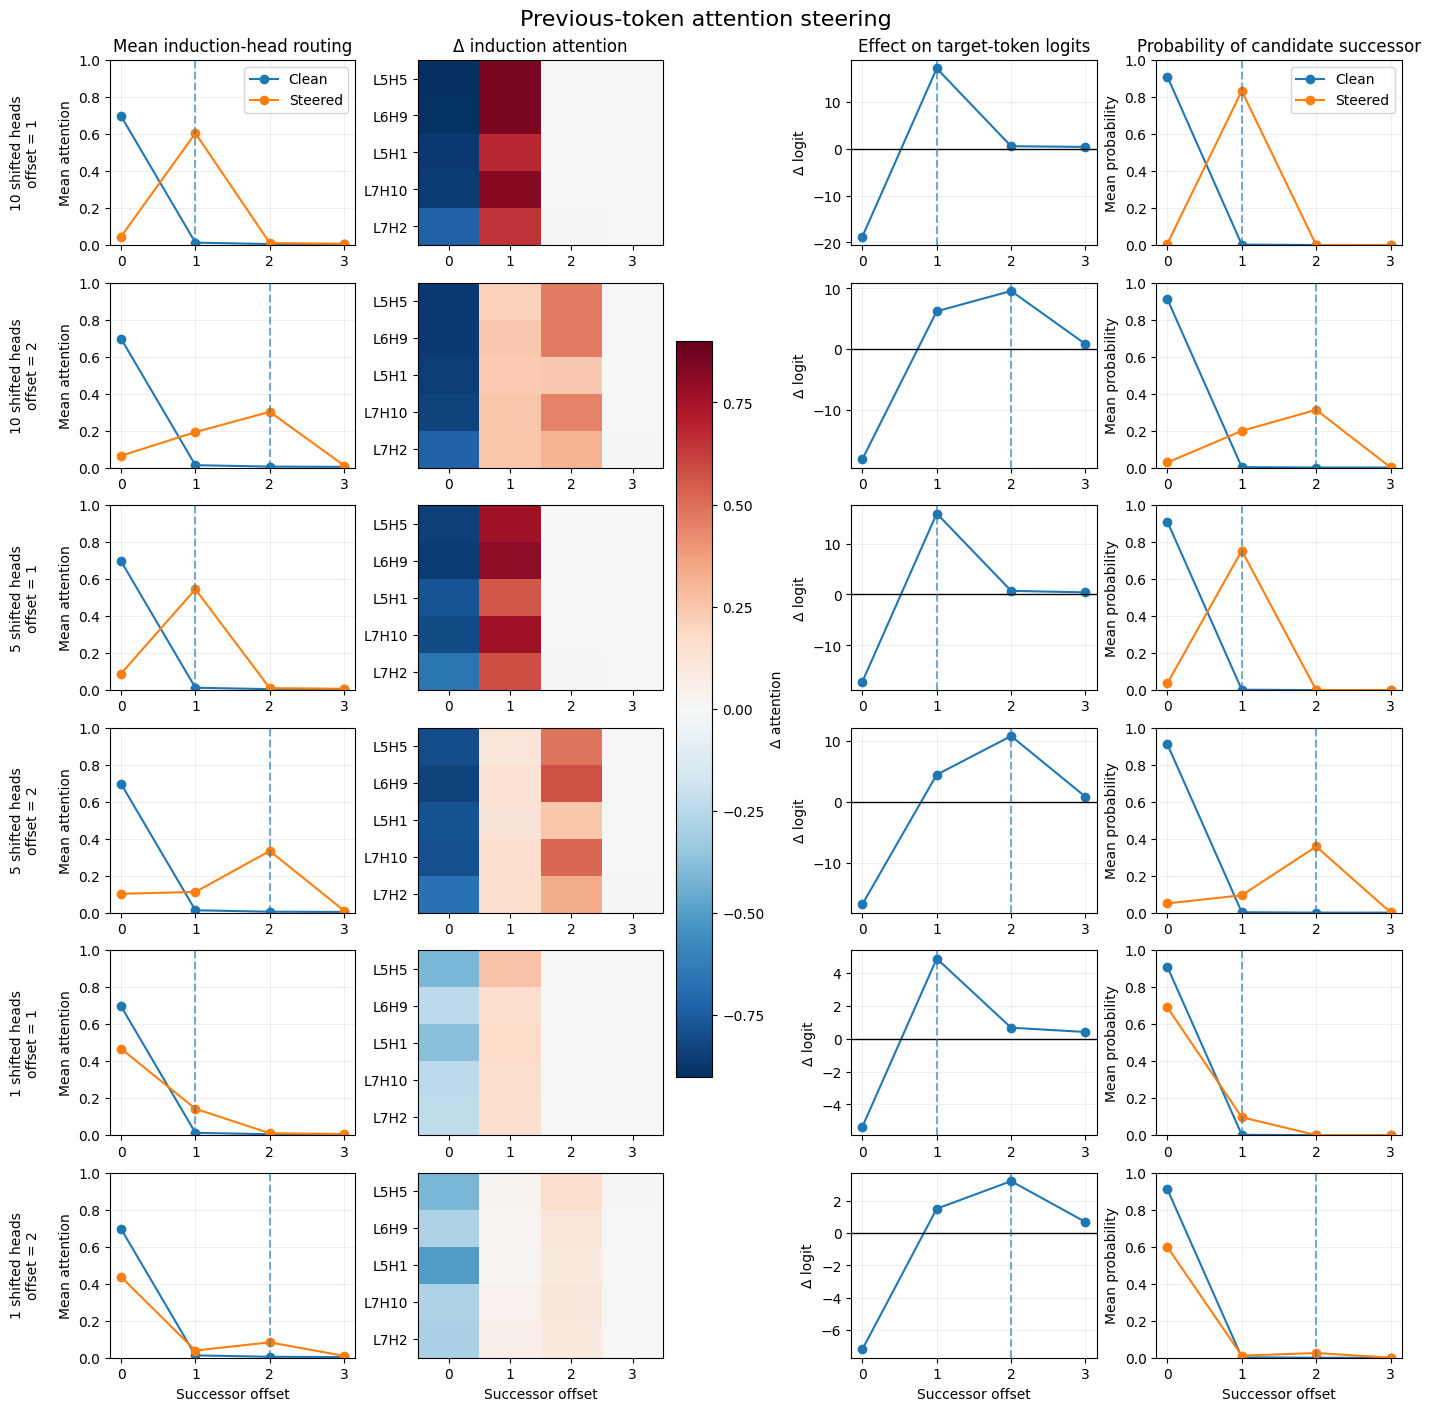

10 shifted heads, offset 1:
  Peak mean attention: 1
  Largest logit increase: 1
  P(target offset 1): 0.002 -> 0.833
10 shifted heads, offset 2:
  Peak mean attention: 2
  Largest logit increase: 2
  P(target offset 2): 0.000 -> 0.312
5 shifted heads, offset 1:
  Peak mean attention: 1
  Largest logit increase: 1
  P(target offset 1): 0.002 -> 0.754
5 shifted heads, offset 2:
  Peak mean attention: 2
  Largest logit increase: 2
  P(target offset 2): 0.000 -> 0.358
1 shifted heads, offset 1:
  Peak mean attention: 0
  Largest logit increase: 1
  P(target offset 1): 0.002 -> 0.097
1 shifted heads, offset 2:
  Peak mean attention: 0
  Largest logit increase: 2
  P(target offset 2): 0.000 -> 0.025


In [ ]:
tokens_device = tokens_batched.to(logits_clean.device)
candidate_offsets = torch.arange(max_offset + 1)

# Use identical positions for every candidate offset
n_positions = seq_len - 1 - max_offset
t = torch.arange(
    n_positions,
    device=logits_clean.device,
)

# Current x_t in second copy
q = seq_len + 1 + t

# Compute results for all conditions
plot_results = {}

for n_heads_to_shift in n_heads_shift_options:

    for offset in offset_options:
        result = multi_offset_mod_results[n_heads_to_shift][offset]
        logits_steered = result["logits"]

        # Attention routing
        attn_clean = torch.zeros(
            len(induction_heads),
            len(candidate_offsets),
        )

        attn_steered = torch.zeros_like(attn_clean)

        for i, (layer, head) in enumerate(induction_heads):
            clean_pattern = cache_clean["pattern", layer]
            steered_pattern = result[layer]

            t_attn = torch.arange(
                n_positions,
                device=clean_pattern.device,
            )

            q_attn = seq_len + 1 + t_attn

            for k in candidate_offsets.tolist():
                source = 2 + t_attn + k
                attn_clean[i, k] = clean_pattern[:, head, q_attn, source].mean().cpu()
                attn_steered[i, k] = steered_pattern[:, head, q_attn, source].mean().cpu()

        # Output effects
        delta_logits = torch.zeros(
            len(candidate_offsets)
        )

        prob_clean = torch.zeros_like(delta_logits)
        prob_steered = torch.zeros_like(delta_logits)

        clean_logprobs = logits_clean.log_softmax(-1)
        steered_logprobs = logits_steered.log_softmax(-1)

        for k in candidate_offsets.tolist():
            target = tokens_device[:, 2 + t + k]
            clean_target_logits = logits_clean[:, q].gather(
                -1,
                target.unsqueeze(-1),
            ).squeeze(-1)
            steered_target_logits = logits_steered[:, q].gather(
                -1,
                target.unsqueeze(-1),
            ).squeeze(-1)
            delta_logits[k] = (
                steered_target_logits
                - clean_target_logits
            ).mean().cpu()

            clean_lp = clean_logprobs[:, q].gather(
                -1,
                target.unsqueeze(-1),
            ).squeeze(-1)
            steered_lp = steered_logprobs[:, q].gather(
                -1,
                target.unsqueeze(-1),
            ).squeeze(-1)

            prob_clean[k] = clean_lp.exp().mean().cpu()
            prob_steered[k] = steered_lp.exp().mean().cpu()

        delta_attn = attn_steered - attn_clean

        if delta_attn.shape[0] >= 5:
            delta_attn = delta_attn[:5]

        plot_results[(n_heads_to_shift, offset)] = {
            "attn_clean": attn_clean,
            "attn_steered": attn_steered,
            "delta_attn": delta_attn,
            "delta_logits": delta_logits,
            "prob_clean": prob_clean,
            "prob_steered": prob_steered,
        }

# Plot everything in one figure
conditions = [
    (n_heads, offset)
    for n_heads in n_heads_shift_options[::-1]
    for offset in offset_options
]

n_rows = len(conditions)

fig, axes = plt.subplots(
    n_rows,
    4,
    figsize=(14, 14),#(18, 3.6 * n_rows),
    constrained_layout=True,
)

fig.suptitle(
    "Previous-token attention steering",
    fontsize=16,
)


# Shared colour scale across all attention heatmaps
attn_vmax = max(
    result["delta_attn"].abs().max().item()
    for result in plot_results.values()
)

attn_vmax = max(attn_vmax, 1e-6)


for row, (n_heads_to_shift, offset) in enumerate(conditions):

    result = plot_results[
        (n_heads_to_shift, offset)
    ]

    attn_clean = result["attn_clean"]
    attn_steered = result["attn_steered"]
    delta_attn = result["delta_attn"]
    delta_logits = result["delta_logits"]
    prob_clean = result["prob_clean"]
    prob_steered = result["prob_steered"]

    # 1. Mean routing
    ax = axes[row, 0]

    ax.plot(
        candidate_offsets,
        attn_clean.mean(dim=0),
        marker="o",
        label="Clean",
    )

    ax.plot(
        candidate_offsets,
        attn_steered.mean(dim=0),
        marker="o",
        label="Steered",
    )

    ax.axvline(
        offset,
        linestyle="--",
        alpha=0.6,
    )

    ax.set_ylim(0, 1)
    ax.set_xticks(candidate_offsets)
    ax.grid(alpha=0.2)

    ax.set_ylabel(
        f"{n_heads_to_shift} shifted heads\n"
        f"offset = {offset}\n\nMean attention"
    )

    if row == 0:
        ax.set_title("Mean induction-head routing")
        ax.legend()

    if row == n_rows - 1:
        ax.set_xlabel("Successor offset")

    # 2. Per-head routing change
    ax = axes[row, 1]

    im = ax.imshow(
        delta_attn,
        cmap="RdBu_r",
        vmin=-attn_vmax,
        vmax=attn_vmax,
        aspect="auto",
    )

    ax.set_xticks(
        np.arange(len(candidate_offsets)),
        candidate_offsets.tolist(),
    )

    ax.set_yticks(
        np.arange(min(len(induction_heads), 5)),
        [
            f"L{layer}H{head}"
            for layer, head in induction_heads[:5]
        ],
    )

    if row == 0:
        ax.set_title("Δ induction attention")

    if row == n_rows - 1:
        ax.set_xlabel("Successor offset")

    # 3. Target-token logit effect
    ax = axes[row, 2]

    ax.plot(
        candidate_offsets,
        delta_logits,
        marker="o",
    )

    ax.axhline(
        0,
        color="black",
        linewidth=1,
    )

    ax.axvline(
        offset,
        linestyle="--",
        alpha=0.6,
    )

    ax.set_xticks(candidate_offsets)
    ax.grid(alpha=0.2)

    if row == 0:
        ax.set_title("Effect on target-token logits")

    if row == n_rows - 1:
        ax.set_xlabel("Successor offset")

    ax.set_ylabel("Δ logit")

    # 4. Actual target probability
    ax = axes[row, 3]

    ax.plot(
        candidate_offsets,
        prob_clean,
        marker="o",
        label="Clean",
    )

    ax.plot(
        candidate_offsets,
        prob_steered,
        marker="o",
        label="Steered",
    )

    ax.axvline(
        offset,
        linestyle="--",
        alpha=0.6,
    )

    ax.set_xticks(candidate_offsets)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.2)

    if row == 0:
        ax.set_title("Probability of candidate successor")
        ax.legend()

    if row == n_rows - 1:
        ax.set_xlabel("Successor offset")

    ax.set_ylabel("Mean probability")


# Single shared colourbar for all heatmaps
fig.colorbar(
    im,
    ax=axes[:, 1],
    label="Δ attention",
    shrink=0.9,
)

plt.show()

# Numerical summary
for n_heads_to_shift, offset in conditions:

    result = plot_results[
        (n_heads_to_shift, offset)
    ]

    print(
        f"{n_heads_to_shift} shifted heads, "
        f"offset {offset}:"
    )

    print(
        "  Peak mean attention:",
        candidate_offsets[
            result["attn_steered"].mean(0).argmax()
        ].item(),
    )

    print(
        "  Largest logit increase:",
        candidate_offsets[
            result["delta_logits"].argmax()
        ].item(),
    )

    print(
        f"  P(target offset {offset}): "
        f"{result['prob_clean'][offset]:.3f} -> "
        f"{result['prob_steered'][offset]:.3f}"
    )


We observe that the behaviour persists across tokens offset 1 and 2 positions, but to a lesser degree for the 2 offset-intervention. Additionally, we observe that for both 5 and 10 head-interventions, the modification has the model predicting the offset target token for both 1 and 2-offsets. When applying the modification only to the one head with the highest previous-token score, the highest log probability remains the original token, but a shift in both induction head attention and model logits (and the corresponding log probabilities) from the original target token to the token at the target position + offset is still directly apparent, as opposed to merely distorted behaviour. We also observe that for an offset of 2, an intervention on 5 heads yields a more clear result than an intervention on 10 heads, yielding a higher log probability on the target token and a smaller non-targeted increase on the token at target + 1. This could be attributable to the fact that heads with a lower previous-token score could only partially fulfill this role. If this is the case, an intervention on them could, beyond a certain previous-token threshold, fulfill a role that is more perturbing of the head's other patterns than of the head's previous-token behaviour, meaning a top 5 head-intervention is a cleaner one despite capturing less of the model's total previous-token attention because it perturbs attention that is not part of the circuit we are trying to intervene on less.

## Conclusion
---
Using repeated random-token sequences, we identified a set of heads displaying an induction attention pattern through positive repetition-associated logit contributions and a large collective ablation effect. We then showed tht redirecting selected previous-token heads within the historical sequence systematically shifts downstream induction-head attention and the model's continuation preferences toward the predicted alternative tokens. This supports a predecessor-dependent retrieval mechanism, while leaving its precise connecting paths and full circuit membership unresolved.